# Dataset exploration: one player trajectory from each dataset

A quick demo that both datasets are available locally and loadable. For each one:
load a match, pick a player, extract their chronological x/y positions, and plot them.

No processing beyond loading. Coordinates are shown as delivered: metres from the
centre spot, with each dataset's own orientation. Run from the repo root's `.venv`;
the first load of a match parses the raw file (~15 s PFF, ~5 s IDSSE) and caches it in
`data/cache/`. Dataset findings are in `docs/DATASET_COMPARISON.md`.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":  # make repo-root imports and data paths work
    os.chdir("..")

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

from src.data_pipeline import idsse_loader, pff_loader


def draw_pitch(ax, length=105.0, width=68.0):
    """Pitch outline, halfway line and centre circle; origin at the centre spot."""
    ax.add_patch(Rectangle((-length / 2, -width / 2), length, width, fill=False, color="0.6", lw=1))
    ax.plot([0, 0], [-width / 2, width / 2], color="0.6", lw=1)
    ax.add_patch(Circle((0, 0), 9.15, fill=False, color="0.6", lw=1))
    ax.set_xlim(-length / 2 - 3, length / 2 + 3)
    ax.set_ylim(-width / 2 - 3, width / 2 + 3)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")


MINUTES = 5  # how much of the first half to plot

## PFF World Cup 2022: Lionel Messi, Poland vs Argentina (match 3850)

Players are identified by team side (0 home, 1 away) and shirt number. Each frame has
raw (`x`, `y`) and smoothed (`xs`, `ys`) positions; we plot the smoothed ones, because
raw positions only change every other frame. The `visibility` flag says whether the
player was on camera (VISIBLE) or their position was estimated by PFF (ESTIMATED).

In [2]:
players, ball = pff_loader.load_tracking("3850")
info = pff_loader.load_match_info("3850")
side, jersey = next(k for k, v in info.players.items() if v["name"] == "Lionel Messi")

messi = players[(players["side"] == side) & (players["jersey"] == jersey) & (players["period"] == 1)]
messi = messi.sort_values("frame")
messi = messi[messi["t"] <= MINUTES * 60]
print(f"{info.home_team} vs {info.away_team}: {len(messi)} frames over {messi['t'].iloc[-1]:.0f} s, "
      f"{(messi['visibility'] == 1).mean():.0%} VISIBLE")
messi[["frame", "t", "x", "y", "xs", "ys", "visibility"]].head()

Poland vs Argentina: 8991 frames over 300 s, 35% VISIBLE


,frame,t,x,y,xs,ys,visibility
16,2470,0.000749,-7.462,12.088,-6.132,12.367,0
38,2471,0.034116,-7.475,12.086,-6.088,12.346,0
60,2472,0.067482,-7.475,12.086,-6.044,12.325,0
82,2473,0.100849,-7.449,11.978,-5.998,12.304,0
104,2474,0.134216,-7.449,11.978,-5.953,12.283,0


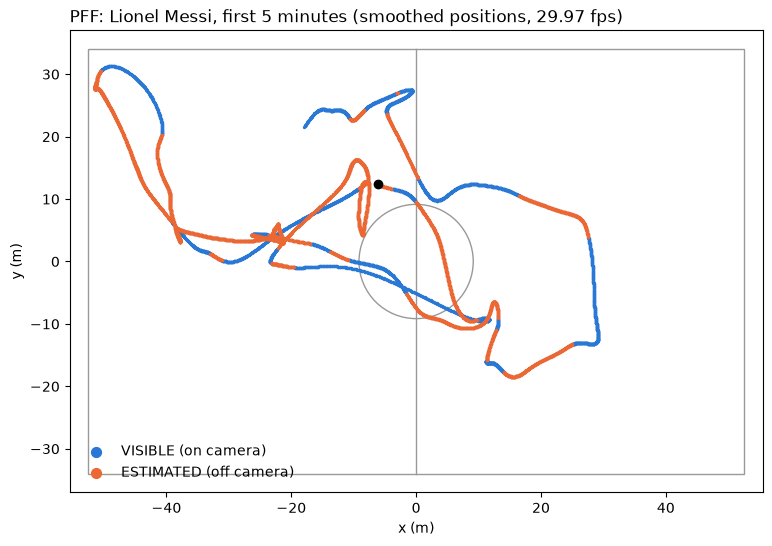

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
draw_pitch(ax)
vis = messi["visibility"] == 1
ax.plot(messi["xs"], messi["ys"], color="0.75", lw=1, zorder=1)
ax.scatter(messi.loc[vis, "xs"], messi.loc[vis, "ys"], s=2, color="#2a78d6", label="VISIBLE (on camera)", zorder=2)
ax.scatter(messi.loc[~vis, "xs"], messi.loc[~vis, "ys"], s=2, color="#eb6834", label="ESTIMATED (off camera)", zorder=2)
ax.plot(*messi[["xs", "ys"]].iloc[0], "ko", ms=6)
ax.set_title(f"PFF: Lionel Messi, first {MINUTES} minutes (smoothed positions, 29.97 fps)", loc="left")
ax.legend(loc="lower left", markerscale=5, frameon=False)
plt.show()

## IDSSE Bundesliga: Thomas Müller, 1. FC Köln vs FC Bayern München (DFL-MAT-J03WMX)

Players have a stable `person_id` (the same across matches). Each player's frames
cover the time they are on the pitch, at 25 Hz, in one position stream (no raw /
smoothed split, no visibility flag: every position comes from in-stadium tracking).

In [4]:
players, ball = idsse_loader.load_positions("DFL-MAT-J03WMX")
info = idsse_loader.load_match_info("DFL-MAT-J03WMX")
person_id = next(pid for pid, p in info["players"].items() if p["name"] == "T. Müller")

muller = players[(players["person_id"] == person_id) & (players["period"] == 1)].sort_values("frame")
muller = muller[muller["frame"] < muller["frame"].min() + MINUTES * 60 * idsse_loader.FPS]
print(f"{info['title']}: {len(muller)} frames over {len(muller) / idsse_loader.FPS:.0f} s")
muller[["frame", "x", "y", "speed"]].head()

1. FC Köln:FC Bayern München: 7500 frames over 300 s


,frame,x,y,speed
70708,10000,-1.53,12.68,0.00
70709,10001,-1.45,12.68,11.34
70710,10002,-1.27,12.65,12.80
70711,10003,-1.07,12.64,14.26
70712,10004,-0.88,12.61,15.70


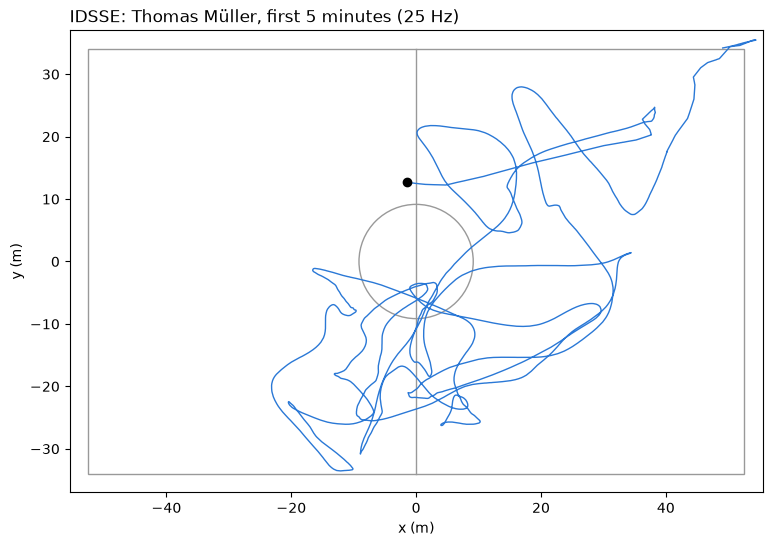

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
draw_pitch(ax, info["pitch_length"], info["pitch_width"])
ax.plot(muller["x"], muller["y"], color="#2a78d6", lw=1)
ax.plot(*muller[["x", "y"]].iloc[0], "ko", ms=6)
ax.set_title(f"IDSSE: Thomas Müller, first {MINUTES} minutes (25 Hz)", loc="left")
plt.show()